In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

df = pd.read_csv("../data/processed/cleaned_dataset.csv")
severity = pd.read_csv("../data/processed/symptom_severity.csv")

os.makedirs("../docs/figures", exist_ok=True)   # folder to save charts
df.shape

(304, 18)

In [2]:
df = df.reset_index().rename(columns={"index": "case_id"})
symptom_cols = [c for c in df.columns if c.startswith("Symptom")]

long = (df.melt(id_vars=["case_id", "Disease"], value_vars=symptom_cols, value_name="Symptom")
          .dropna(subset=["Symptom"]))

X = pd.crosstab(long["case_id"], long["Symptom"]).clip(upper=1)
y = df.set_index("case_id").loc[X.index, "Disease"]

print("Feature table:", X.shape)
X.head()

Feature table: (304, 131)


Symptom,abdominal_pain,abnormal_menstruation,acidity,acute_liver_failure,altered_sensorium,anxiety,back_pain,belly_pain,blackheads,bladder_discomfort,...,vomiting,watering_from_eyes,weakness_in_limbs,weakness_of_one_body_side,weight_gain,weight_loss,yellow_crust_ooze,yellow_urine,yellowing_of_eyes,yellowish_skin
case_id,,,,,,,,,,,,,,,,,,,,,
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
long = long.merge(severity, on="Symptom", how="left")

case_severity = long.groupby("case_id").agg(
    num_symptoms=("Symptom", "count"),
    total_severity=("weight", "sum"),
    max_severity=("weight", "max"),
)
case_severity["Disease"] = y
case_severity.head()

,num_symptoms,total_severity,max_severity,Disease
case_id,,,,
0,4,14,6,Fungal infection
1,3,13,6,Fungal infection
2,3,11,6,Fungal infection
3,3,10,6,Fungal infection
4,3,8,4,Fungal infection


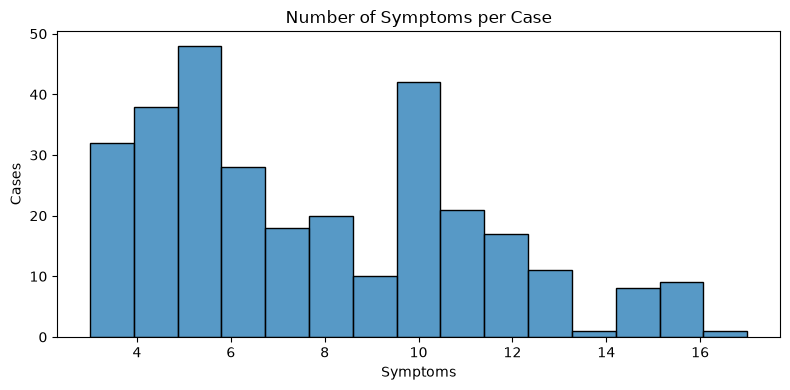

In [4]:
plt.figure(figsize=(8, 4))
sns.histplot(case_severity["num_symptoms"], bins=15)
plt.title("Number of Symptoms per Case")
plt.xlabel("Symptoms")
plt.ylabel("Cases")
plt.tight_layout()
plt.savefig("../docs/figures/symptoms_per_case.png", dpi=150)
plt.show()

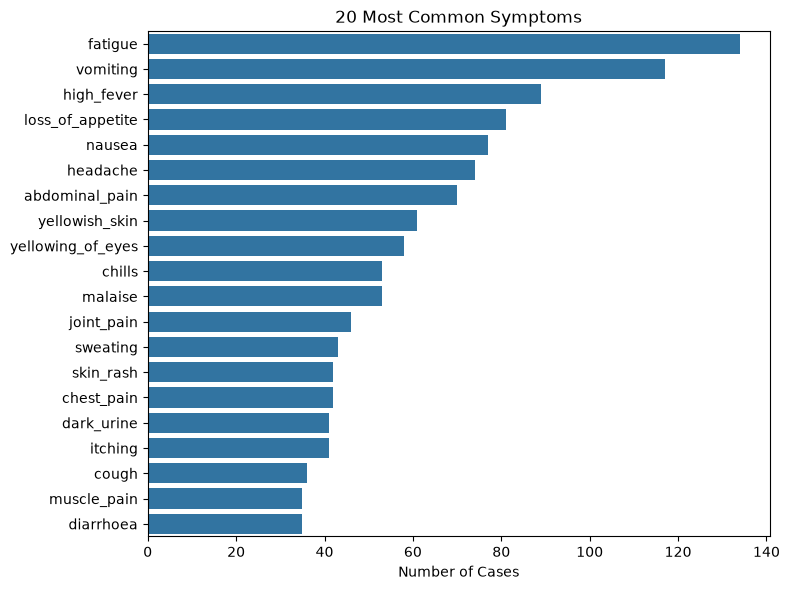

In [5]:
top = X.sum().sort_values(ascending=False).head(20)

plt.figure(figsize=(8, 6))
sns.barplot(x=top.values, y=top.index)
plt.title("20 Most Common Symptoms")
plt.xlabel("Number of Cases")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../docs/figures/top_symptoms.png", dpi=150)
plt.show()

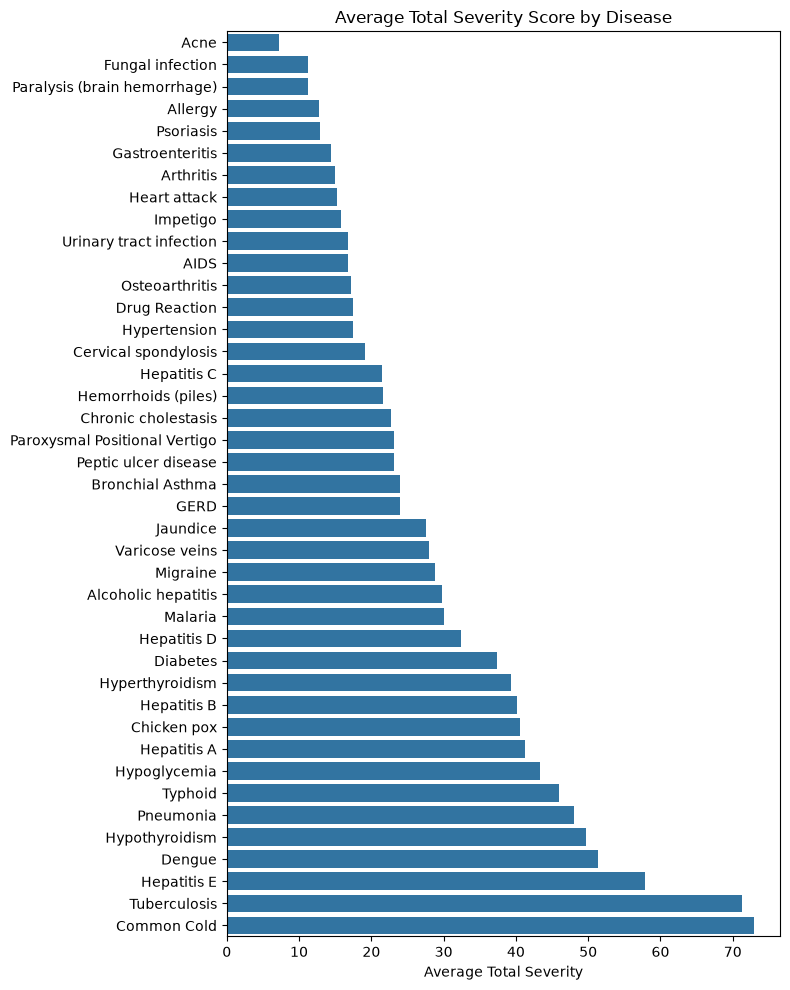

In [6]:
avg = case_severity.groupby("Disease")["total_severity"].mean().sort_values()

plt.figure(figsize=(8, 10))
sns.barplot(x=avg.values, y=avg.index)
plt.title("Average Total Severity Score by Disease")
plt.xlabel("Average Total Severity")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../docs/figures/severity_by_disease.png", dpi=150)
plt.show()

In [7]:
X.to_csv("../data/processed/X_features.csv")
y.to_csv("../data/processed/y_labels.csv")
case_severity.to_csv("../data/processed/case_severity.csv")
print("Saved!")

Saved!


In [8]:
print("Correlation between symptom count and total severity:",
      round(case_severity["num_symptoms"].corr(case_severity["total_severity"]), 2))

comp = case_severity.groupby("Disease")[["num_symptoms", "total_severity", "max_severity"]].mean().round(1)
comp.loc[["Common Cold", "Tuberculosis", "Heart attack", "Paralysis (brain hemorrhage)"]]

Correlation between symptom count and total severity: 0.97


,num_symptoms,total_severity,max_severity
Disease,,,
Common Cold,16.1,72.9,7.0
Tuberculosis,15.1,71.3,7.0
Heart attack,3.2,15.2,6.6
Paralysis (brain hemorrhage),3.2,11.2,4.8


In [9]:
cold = (long[long["Disease"] == "Common Cold"][["Symptom", "weight"]]
        .drop_duplicates()
        .sort_values("weight", ascending=False))
cold.head(10)

,Symptom,weight
1091,high_fever,7
2288,chest_pain,7
1718,malaise,6
1550,swelled_lymph_nodes,6
2230,runny_nose,5
2089,redness_of_eyes,5
2268,congestion,5
1859,phlegm,5
198,continuous_sneezing,4
2173,sinus_pressure,4
